# EDA 01a — IBM Telco Customer Churn

**Mục tiêu:** Khám phá dữ liệu `WA_Fn-UseC_-Telco-Customer-Churn.csv`, kiểm tra chất lượng dữ liệu, phân bố nhãn, mối quan hệ giữa các biến với `Churn`, hiện tượng dư thừa của `TotalCharges`, và rút ra danh sách **"Phát hiện → Hệ quả cho mô hình"**.

> **Lưu ý tải dữ liệu:** Dataset IBM trên Kaggle yêu cầu đăng nhập. Tải tay file `WA_Fn-UseC_-Telco-Customer-Churn.csv` đặt vào `data/raw/` và kiểm tra bằng `python -m src.download_data --check-only` trước khi chạy toàn bộ notebook.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

FIGURES_EDA_DIR = PROJECT_ROOT / "figures" / "eda"
FIGURES_EDA_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 150
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", palette="colorblind")
print("PROJECT_ROOT:", PROJECT_ROOT)
print("FIGURES_EDA_DIR:", FIGURES_EDA_DIR)

PROJECT_ROOT: C:\Users\Admin\Documents\ML\telco-churn-prediction
FIGURES_EDA_DIR: C:\Users\Admin\Documents\ML\telco-churn-prediction\figures\eda


## 1. Nạp dữ liệu, kích thước, kiểu dữ liệu & giá trị thiếu

In [2]:
IBM_PATH = PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not IBM_PATH.exists():
    raise FileNotFoundError(
        f"Chưa tìm thấy {IBM_PATH}. Tải từ https://www.kaggle.com/datasets/blastchar/telco-customer-churn"
    )

raw_df = pd.read_csv(IBM_PATH)
print(f"Kích thước: {raw_df.shape[0]:,} dòng × {raw_df.shape[1]} cột")
display(raw_df.head(3))
display(raw_df.dtypes.to_frame("dtype"))

Kích thước: 7,043 dòng × 21 cột


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


,dtype
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


In [3]:
# Kiểm tra TotalCharges dạng chuỗi trước khi ép kiểu số
df = raw_df.copy()
df["TotalCharges_num"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing_tc = df[df["TotalCharges_num"].isna()]
print(f"Số ô trống / không hợp lệ ở TotalCharges: {len(missing_tc)}")
print("Phân bố tenure của các dòng thiếu TotalCharges:")
print(missing_tc["tenure"].value_counts(dropna=False))
display(missing_tc[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

Số ô trống / không hợp lệ ở TotalCharges: 11
Phân bố tenure của các dòng thiếu TotalCharges:
tenure
0    11
Name: count, dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Giải thích kỹ thuật:** Tất cả 11 giá trị trống ở `TotalCharges` đều rơi vào khách hàng mới (`tenure == 0`). Khi dùng `pd.to_numeric(..., errors="coerce")`, chúng trở thành `NaN`. Do đó, bước **imputation (median)** bắt buộc phải nằm **bên trong pipeline (`sklearn`)** để fit trên tập train và biến đổi nhất quán trên validation/test/dữ liệu thực tế, tránh rò rỉ dữ liệu.

## 2. Kiểm tra dòng trùng lặp & phân bố nhãn (mất cân bằng)

Số customerID trùng lặp: 0
Số dòng trùng hoàn toàn: 0
Tỉ lệ Churn: 26.54% (1,869 / 7,043)


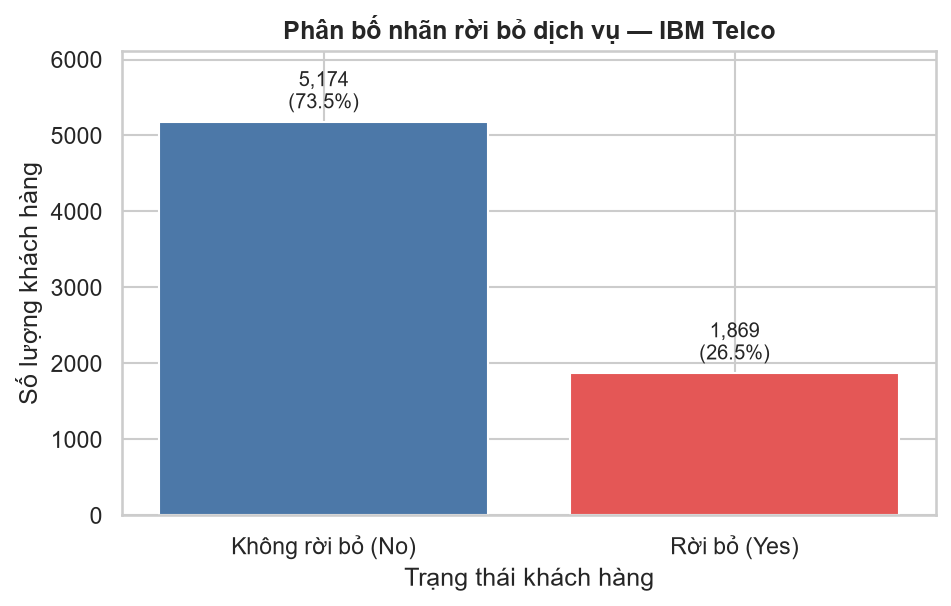

In [4]:
print("Số customerID trùng lặp:", df["customerID"].duplicated().sum())
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())

df["Churn_bin"] = df["Churn"].astype(str).str.strip().map({"Yes": 1, "No": 0})
churn_counts = df["Churn"].value_counts()
churn_rate = df["Churn_bin"].mean()
print(f"Tỉ lệ Churn: {churn_rate:.2%} ({churn_counts.get('Yes', 0):,} / {len(df):,})")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
colors = ["#4C78A8", "#E45756"]
bars = ax.bar(["Không rời bỏ (No)", "Rời bỏ (Yes)"], [churn_counts["No"], churn_counts["Yes"]], color=colors)
for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h:,}\n({h / len(df):.1%})", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9.5)
ax.set_title("Phân bố nhãn rời bỏ dịch vụ — IBM Telco", fontweight="bold")
ax.set_xlabel("Trạng thái khách hàng")
ax.set_ylabel("Số lượng khách hàng")
ax.set_ylim(0, max(churn_counts) * 1.18)
fig.tight_layout()
fig.savefig(FIGURES_EDA_DIR / "ibm_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Tỉ lệ Churn theo các biến phân loại trọng tâm

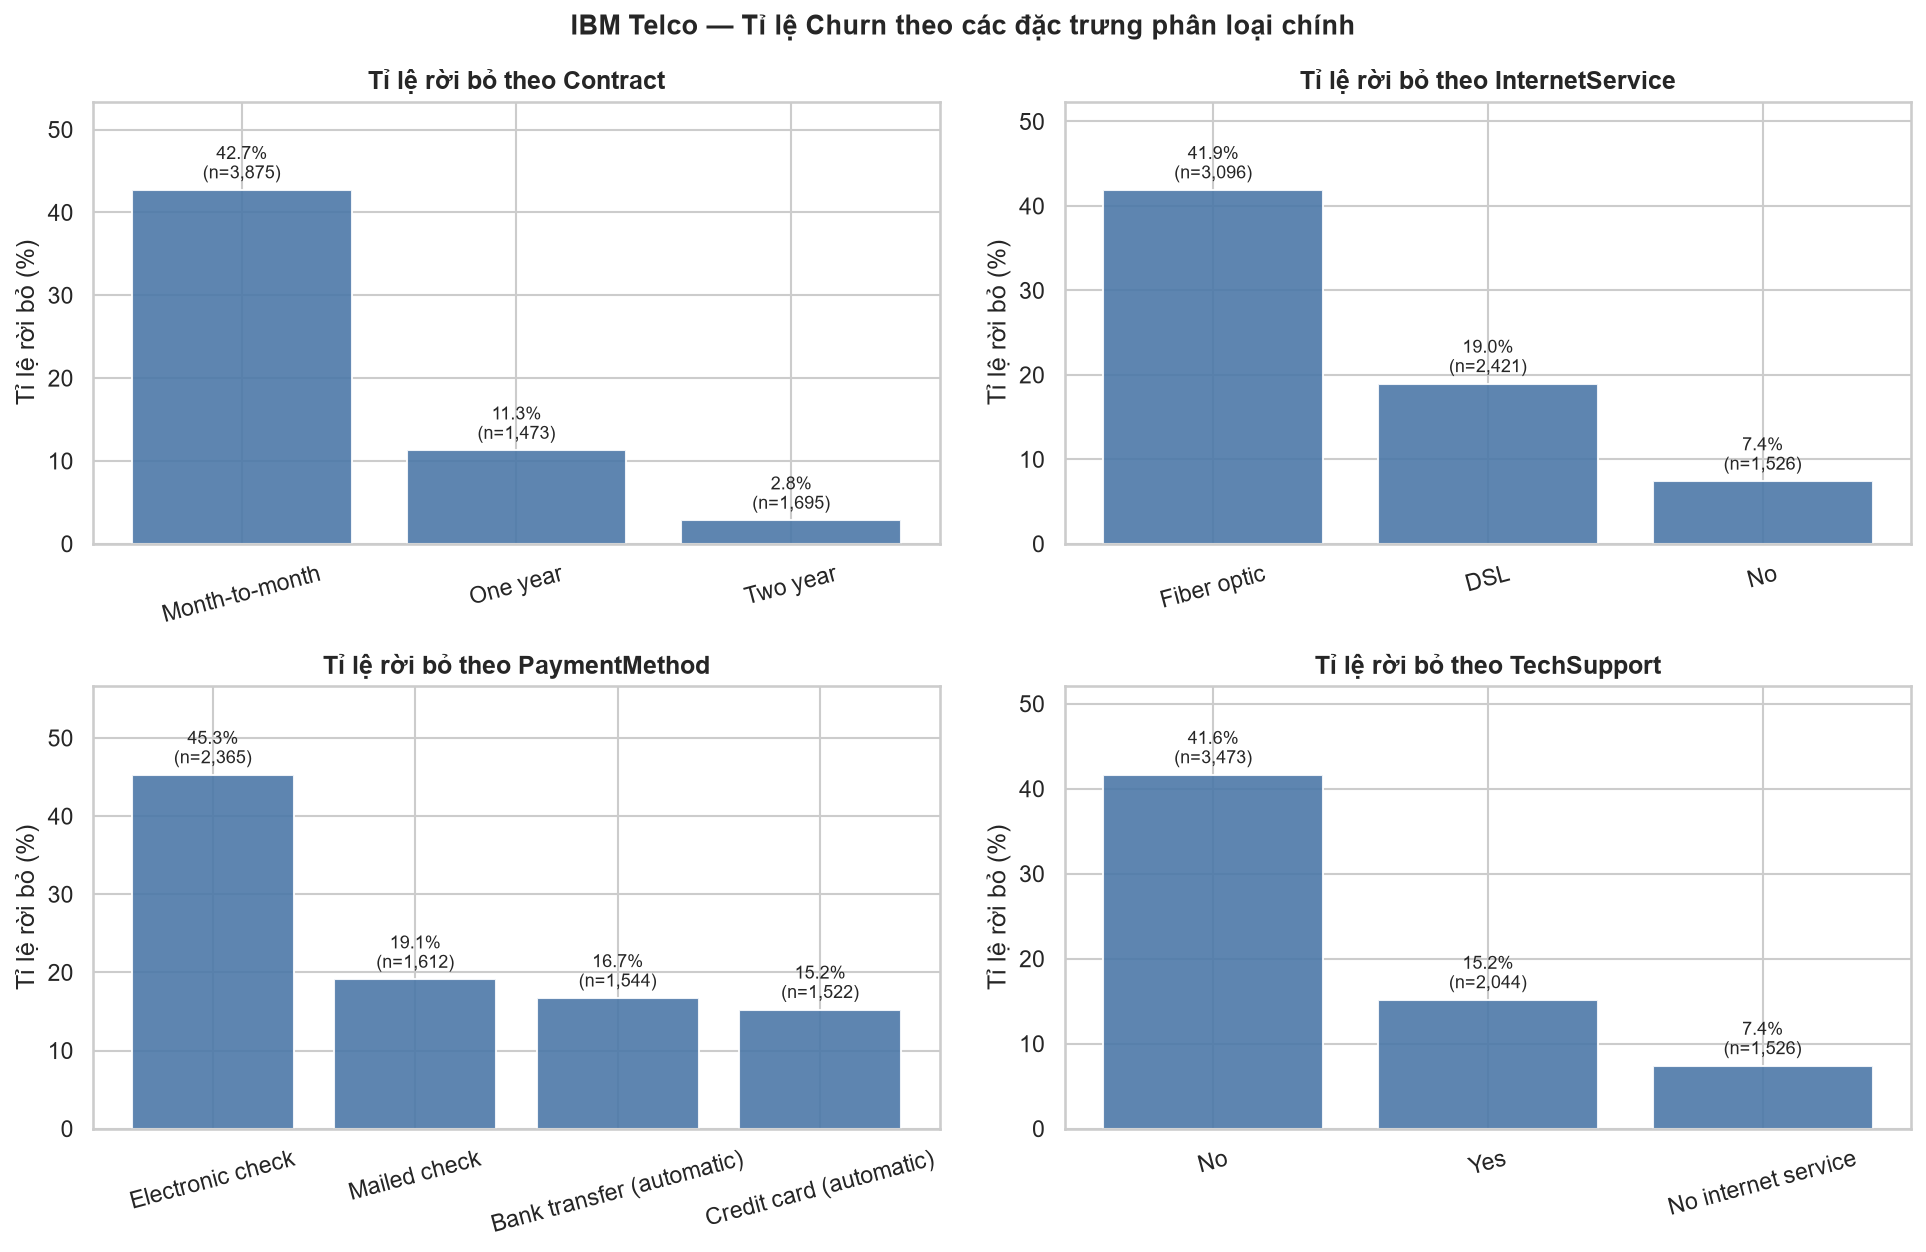

In [5]:
cat_cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

for ax, col in zip(axes.ravel(), cat_cols):
    summary = df.groupby(col)["Churn_bin"].agg(["mean", "count"]).sort_values("mean", ascending=False)
    bars = ax.bar(summary.index.astype(str), summary["mean"] * 100, color="#4C78A8", alpha=0.9)
    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.annotate(f"{row['mean']:.1%}\n(n={int(row['count']):,})",
                    xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8.5)
    ax.set_title(f"Tỉ lệ rời bỏ theo {col}", fontweight="bold")
    ax.set_ylabel("Tỉ lệ rời bỏ (%)")
    ax.set_ylim(0, max(summary["mean"] * 100) * 1.25)
    ax.tick_params(axis="x", rotation=15)

fig.suptitle("IBM Telco — Tỉ lệ Churn theo các đặc trưng phân loại chính", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_EDA_DIR / "ibm_categorical_churn.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Phân bố biến số theo nhãn (`tenure`, `MonthlyCharges`)

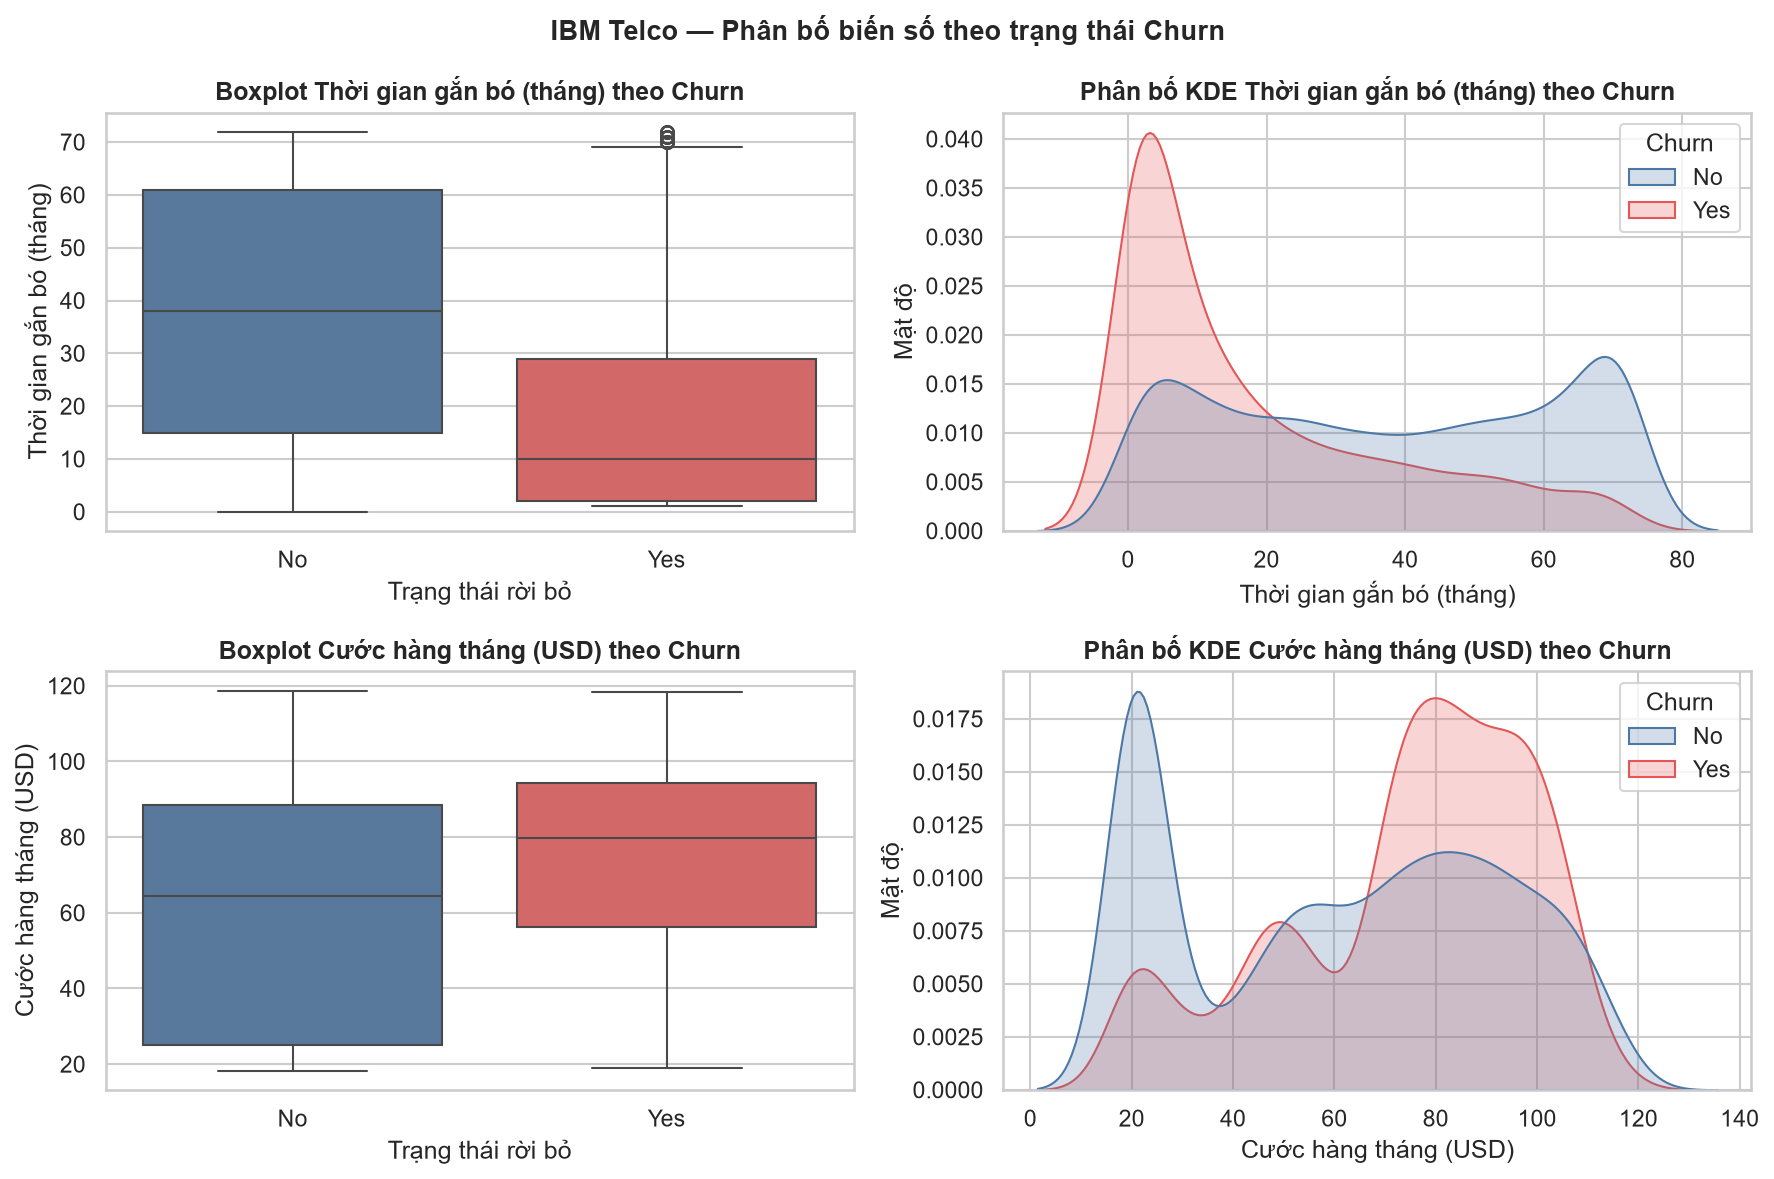

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for idx, (col, label_vi) in enumerate([("tenure", "Thời gian gắn bó (tháng)"), ("MonthlyCharges", "Cước hàng tháng (USD)")]):
    sns.boxplot(data=df, x="Churn", y=col, hue="Churn", palette={"No": "#4C78A8", "Yes": "#E45756"},
                legend=False, ax=axes[idx, 0])
    axes[idx, 0].set_title(f"Boxplot {label_vi} theo Churn", fontweight="bold")
    axes[idx, 0].set_xlabel("Trạng thái rời bỏ")
    axes[idx, 0].set_ylabel(label_vi)

    sns.kdeplot(data=df, x=col, hue="Churn", fill=True, common_norm=False,
                palette={"No": "#4C78A8", "Yes": "#E45756"}, ax=axes[idx, 1])
    axes[idx, 1].set_title(f"Phân bố KDE {label_vi} theo Churn", fontweight="bold")
    axes[idx, 1].set_xlabel(label_vi)
    axes[idx, 1].set_ylabel("Mật độ")

fig.suptitle("IBM Telco — Phân bố biến số theo trạng thái Churn", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_EDA_DIR / "ibm_numeric_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Ma trận tương quan & kiểm chứng biến dư thừa `TotalCharges`

Hệ số tương quan Pearson (TotalCharges vs tenure × MonthlyCharges): r = 0.999560
Hệ số xác định R^2 (TotalCharges ≈ tenure × MonthlyCharges): R^2 = 0.999120


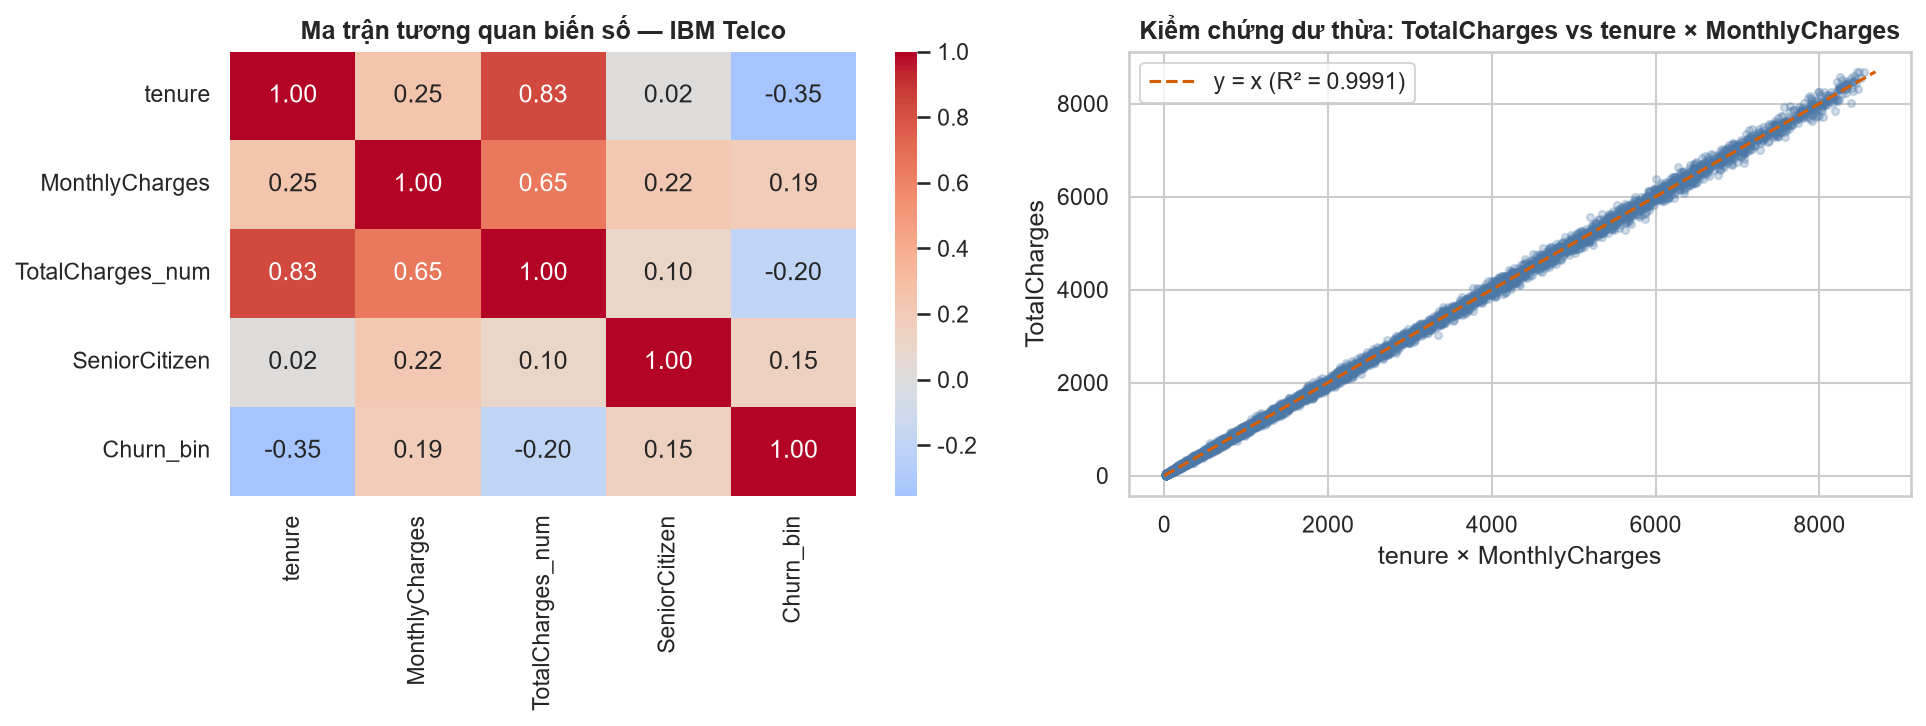

In [7]:
valid_tc = df.dropna(subset=["TotalCharges_num"]).copy()
valid_tc["expected_total"] = valid_tc["tenure"] * valid_tc["MonthlyCharges"]
corr_matrix = valid_tc[["tenure", "MonthlyCharges", "TotalCharges_num", "SeniorCitizen", "Churn_bin"]].corr()

# Tính R^2 giữa TotalCharges và tenure * MonthlyCharges
ss_res = np.sum((valid_tc["TotalCharges_num"] - valid_tc["expected_total"]) ** 2)
ss_tot = np.sum((valid_tc["TotalCharges_num"] - valid_tc["TotalCharges_num"].mean()) ** 2)
r2_tc = 1.0 - ss_res / ss_tot
corr_tc = valid_tc["TotalCharges_num"].corr(valid_tc["expected_total"])
print(f"Hệ số tương quan Pearson (TotalCharges vs tenure × MonthlyCharges): r = {corr_tc:.6f}")
print(f"Hệ số xác định R^2 (TotalCharges ≈ tenure × MonthlyCharges): R^2 = {r2_tc:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Ma trận tương quan biến số — IBM Telco", fontweight="bold")

axes[1].scatter(valid_tc["expected_total"], valid_tc["TotalCharges_num"], alpha=0.25, s=12, color="#4C78A8")
max_val = max(valid_tc["expected_total"].max(), valid_tc["TotalCharges_num"].max())
axes[1].plot([0, max_val], [0, max_val], "r--", linewidth=1.5, label=f"y = x (R² = {r2_tc:.4f})")
axes[1].set_title("Kiểm chứng dư thừa: TotalCharges vs tenure × MonthlyCharges", fontweight="bold")
axes[1].set_xlabel("tenure × MonthlyCharges")
axes[1].set_ylabel("TotalCharges")
axes[1].legend()

fig.tight_layout()
fig.savefig(FIGURES_EDA_DIR / "ibm_totalcharges_redundancy.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Phát hiện → Hệ quả cho mô hình

1. **Mất cân bằng lớp (~26.5% churn):** Không thể chỉ dùng Accuracy vì mô hình đoán toàn `No` vẫn đạt ~73.5%. → **Hệ quả:** Đánh giá chính bằng PR-AUC (Average Precision), F1-score lớp Churn, Recall và tối ưu ngưỡng theo chi phí kinh doanh trên tập validation; dùng `class_weight="balanced"`.
2. **11 ô trống ở `TotalCharges` đều có `tenure = 0`:** Thiếu dữ liệu có cấu trúc (khách hàng mới chưa có hóa đơn tổng). → **Hệ quả:** Ép kiểu số và đặt `SimpleImputer` trong `sklearn` pipeline để tránh data leakage khi chia train/val/test.
3. **`TotalCharges ≈ tenure × MonthlyCharges` ($R^2 > 0.99$):** Gây đa cộng tuyến nặng cho mô hình tuyến tính (`LogReg`, `SVM_Linear`). → **Hệ quả:** Chính sách mặc định loại bỏ `TotalCharges` và thực hiện thí nghiệm **Ablation A1** (giữ vs bỏ) để định lượng tác động.
4. **Biến phân loại có tín hiệu phân tách mạnh (`Contract`, `InternetService`, `PaymentMethod`, `TechSupport`):** Hợp đồng theo tháng và cáp quang có tỉ lệ churn cao hơn hẳn. → **Hệ quả:** Mã hóa One-Hot và tạo đặc trưng tương tác (như `is_high_risk_contract`, `charges_per_tenure`) trong `TelcoFeatureEngineer`.